# 06 — A toy global workspace

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/06_global_workspace.ipynb)

**Related resources:** [Paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) · [Presentation guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md)

## Why this notebook

Global-workspace theories motivate a distinction between local processing and information that becomes broadly available to other processes. A small threshold-and-capacity model can make some of that vocabulary concrete. Here eight named activity variables receive weak or strong drive; above-threshold winners can occupy up to two slots and receive sustaining feedback.

You will follow how input strength, decay, threshold and capacity affect persistence. The schematic labels provide a vocabulary for access and communication; the recurrence below specifies exactly which feedback is implemented.

### Learning goals

1. Separate input strength, activity, slot occupancy and sustained activation.
2. Explain how threshold and feedback can create a sharp-looking transition.
3. Distinguish an architectural analogy from a test of a consciousness theory.
4. State what additional observations would support a claim about global availability.


## Concepts and two reading paths

<details open>
<summary><strong>For biomedical and imaging readers</strong></summary>

**Local processing** means information can affect a subsystem without being available to all other processes. **Global availability** is a theoretical claim about wider use, for example in report, planning or action. A label in a schematic is not a direct measurement of either process.

**Ignition** in this toy is the first time at least one activity passes the occupancy threshold. **Capacity** limits the number of selected above-threshold modules. **Feedback** adds support to selected activities, which can let them persist after a pulse ends.

The words "vision," "plan" and "affect" label variables; these modules do not actually recognize images, formulate plans or represent emotions. Begin by reading their traces as numbers obeying the recurrence, then consider what a fuller model would need to implement.

</details>

<details>
<summary><strong>For computational readers</strong></summary>

Let $a_t$ be the activity vector, $d_t$ the drive and $m(a_t)$ the binary mask selecting at most the capacity limit among above-threshold activities. The implemented update is

$$a_{t+1}=\operatorname{clip}\big[(1-\delta)a_t+d_t+g\,m(a_t),0,1\big].$$

The discontinuous mask and positive feedback are built into the model. A sharp occupancy curve is therefore partly a consequence of the selection rule; it is not independent evidence that a threshold was discovered in data. With drive held fixed, changing $g$, $\delta$, threshold or capacity probes the recurrence itself.

Global broadcast in a richer model would specify which recipient states change, what information they receive and how that affects subsequent computation. This recurrence does not implement all of those operations. Treat the diagram and the numerical mechanism at their respective levels of detail.

</details>


### Run in Colab or locally

**Colab:** click **Open in Colab**, connect to a standard **CPU** runtime, and run the setup cell followed by the remaining cells (**Runtime → Run all**). Setup obtains the shared code and numerical dependencies.

**Locally:** follow the [environment instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks) and select the project's Python kernel in Cursor or JupyterLab. Setup locates the checkout and sets the working directory to `code/notebooks`, so `%load ../solutions/<filename>.py` works in either environment.

Use **File → Save a copy in Drive** to retain Colab notebook edits, and download generated files before the runtime ends. See the [execution guide](https://github.com/arvidl/brains-to-models/blob/main/code/notebooks/README.md#running-and-saving) for saving outputs and starting a fresh runtime.


In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.

from brainsmodels.repro import DEFAULT_SEED, set_seed
from brainsmodels.workspace import (
    CAPACITY,
    MODULE_NAMES,
    N_MODULES,
    THRESHOLD,
    facts,
    render_paper_figure,
    run_experiment,
    write_figure,
)

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("repo root:", root)
print("seed:", SEED)
print(f"{N_MODULES} modules, {CAPACITY} slots, θ = {THRESHOLD}")

Checkout: CHECKOUT
Python: 3.12.2 | NumPy: 2.5.2
repo root: CHECKOUT
seed: 7
8 modules, 2 slots, θ = 0.55


## The schematic

Eight modules $m=1,\ldots,8$ carry a scalar activity $s_m\in[0,1]$. A workspace of $k=2$ slots is empty unless someone has crossed a threshold $\theta$:

$$
\mathrm{occupy}(s)=\begin{cases}
\text{the }k\text{ strongest }m\text{ with }s_m\ge\theta & \text{if any such }m\text{ exist,}\\
\emptyset & \text{otherwise.}
\end{cases}
$$

Each step is local decay, an external drive, and a broadcast bonus for whoever is in:

$$
s\leftarrow\mathrm{clip}\bigl((1-\delta)\,s+d_t+\beta\,\mathbf{1}_{\mathrm{occupy}(s)},\,0,1\bigr).
$$

Compare weak and strong drives with the same threshold and capacity. Positive feedback can sustain activity after workspace entry. Module names are teaching labels; this update is not fitted to a biological circuit.

**Before running.** Locate the pulse, activity trace and occupancy mask as three separate objects. The mask is computed from activity by a threshold-and-ranking rule, rather than measured independently. Before calling a sharp transition an emergent discovery, identify which discontinuity was inserted directly into that rule.


weak_ignited           False
weak_peak_activity     0.4056743920844766
weak_occupants         ()
strong_ignited         True
strong_ignition_t      10
strong_peak_activity   1.0
strong_occupants       ('count', 'plan')
Gurnee et al. 2026: J-space component is a small slice (concept-vector median ~6–7%; activation variance never >10%). Not measured here.


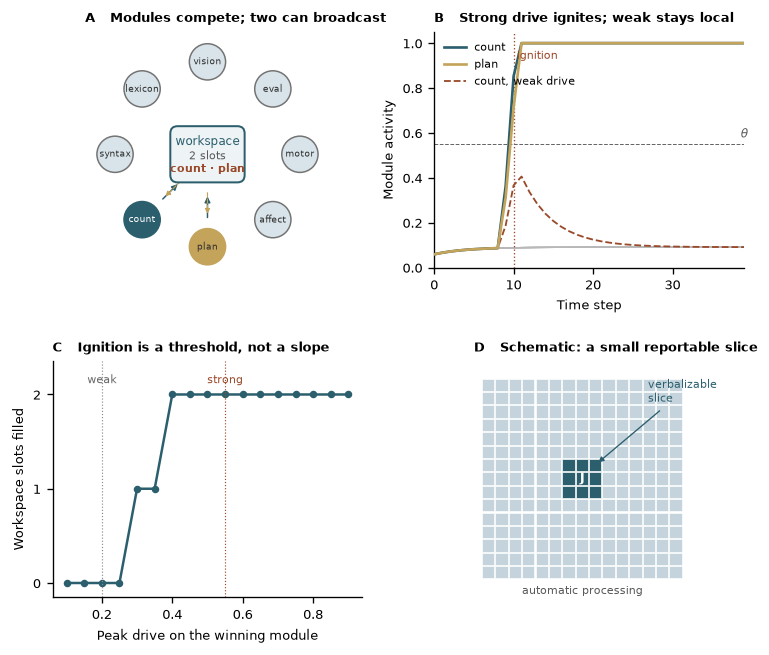

wrote CHECKOUT/paper/figures/global_workspace.pdf
wrote CHECKOUT/paper/figures/global_workspace.png


PosixPath('CHECKOUT/paper/figures/global_workspace.pdf')

In [2]:
result = run_experiment(seed=SEED)
info = facts(result)
for key in (
    "weak_ignited",
    "weak_peak_activity",
    "weak_occupants",
    "strong_ignited",
    "strong_ignition_t",
    "strong_peak_activity",
    "strong_occupants",
):
    print(f"{key:22s} {info[key]}")
print(info["jspace_variance_note"])
fig = render_paper_figure(result)
plt.show()
write_figure(result, root / "paper" / "figures")

## What to read from the weak and strong runs

Compare the input pulse with the activity traces before looking at the occupancy mask. A transient rise below threshold is still numerical processing. Selection adds feedback, and the combination can sustain activity after the pulse. The mask then reports which variables satisfy the occupancy rule, rather than a separate measurement of access or report.

The capacity setting provides an upper bound on occupied slots, not a fitted estimate of human working-memory capacity. The default threshold, pulse shapes and module labels are chosen teaching parameters. They should not be interpreted as physiological constants.

### An intervention that tests the mechanism

Remove sustaining feedback while keeping the input pulse fixed. Predict whether activity remains high after the pulse. Next vary threshold while leaving the recurrence otherwise unchanged. These tests distinguish a consequence of feedback from a consequence of thresholding. Changing the drive, feedback and threshold together would obscure that distinction.

To study availability, extend the model with a recipient that must use selected information in a second task. Compare what that recipient can do with and without the proposed communication pathway. A persistent variable alone would not establish the pathway's function.

### Relation to consciousness and language-model research

A claim about conscious access needs an operational measure, such as successful use of selected information in a second task or report. For the language-model studies in the reading list, identify that measure and the interventions that test it. Compare those operations with the recurrence implemented here.

**Check your understanding.** Could a system keep information locally without crossing this threshold? Could a globally useful representation exist without this exact two-slot rule? Both are possible. Specify a task and a measurable consequence before using a familiar term as an architectural verdict.


## Comparison with language-model research

The study [Verbalizable Representations Form a Global Workspace in Language Models](https://transformer-circuits.pub/2026/workspace) investigates functional access with its own measurements and interventions. This toy does not reproduce those experiments. Distinguish functional access from claims about subjective experience.


### Exercises

1. **Raise the threshold.** Ignition is `activity >= THRESHOLD` (default 0.55). Hold a mid-strength pulse (`peak=0.35`, no runner) and re-run at thresholds 0.40, 0.55, and 0.70. Who occupies the workspace, and at which threshold does the same drive stay local?

<!-- solution-box: 06_1_raise_the_threshold.py -->
<details>
<summary><strong>Show solution</strong> — Raise the threshold</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/06_1_raise_the_threshold.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

import brainsmodels.workspace as ws
old = ws.THRESHOLD
try:
    for thr in (0.40, 0.55, 0.70):
        ws.THRESHOLD = thr
        trial = ws.run_trial("mid", 0.35, 0.0)
        print(
            f"θ={thr:.2f}  ignited={trial.ignited}  "
            f"t={trial.ignition_t}  occupants={trial.occupants}"
        )
finally:
    ws.THRESHOLD = old
print('Compare workspace occupancy for identical input at different thresholds. Ignition is defined by the model rule; it is not an independent consciousness measurement.')
```

</details>
<!-- /solution-box -->


2. **One slot.** Capacity is two. Set `CAPACITY = 1` and re-run the strong trial. Which module is dropped, and what does a one-slot workspace say about “everything that is active is reportable”?

<!-- solution-box: 06_2_one_slot.py -->
<details>
<summary><strong>Show solution</strong> — One slot</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/06_2_one_slot.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

import brainsmodels.workspace as ws
old = ws.CAPACITY
try:
    two = ws.run_trial("cap2", ws.STRONG_PEAK, ws.RUNNER_PEAK)
    ws.CAPACITY = 1
    one = ws.run_trial("cap1", ws.STRONG_PEAK, ws.RUNNER_PEAK)
finally:
    ws.CAPACITY = old
print("capacity 2 occupants:", two.occupants)
print("capacity 1 occupants:", one.occupants)
print('A one-slot buffer excludes some active modules from broadcast. This demonstrates capacity-limited access under the chosen selection rule.')
```

</details>
<!-- /solution-box -->


3. **Lesion the winner.** The intended winner is `count` (module 3). Run a trial whose pulse is only on the runner (`peak=0`, `runner=STRONG_PEAK`). Who ignites? What does a lesion of the would-be winner show about “the workspace chose the meaning”?

<!-- solution-box: 06_3_lesion_the_winner.py -->
<details>
<summary><strong>Show solution</strong> — Lesion the winner</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/06_3_lesion_the_winner.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

import brainsmodels.workspace as ws
intact = ws.run_trial("intact", ws.STRONG_PEAK, ws.RUNNER_PEAK)
lesion = ws.run_trial("lesion count", 0.0, ws.STRONG_PEAK)
print("intact :", intact.occupants, "ignition_t", intact.ignition_t)
print("lesion :", lesion.occupants, "ignition_t", lesion.ignition_t)
print('Removing one drive changes which module crosses the threshold and enters the workspace. The experiment tests the implemented selection rule.')
```

</details>
<!-- /solution-box -->


### Questions for reflection

Use these questions to distinguish what the calculation shows from the assumptions and interpretations attached to it. Write an answer before consulting the instructor notes.


1. Which workspace operations are implemented?

2. What does the threshold comparison establish?

3. What intervention would test the role of broadcast?

4. What can this model say about subjective experience?

5. How should language-model workspace findings be compared with the toy?


### Further reading

1. **Baars, B. J. (2002).** [*The conscious access hypothesis: origins and recent evidence*](https://doi.org/10.1016/S1364-6613(00)01819-2). *Trends in Cognitive Sciences* 6(1), 47–52.
2. **Block, N. (1995).** [*On a confusion about a function of consciousness*](https://divinecuration.github.io/assets/pdf/block-confusion.pdf). *Behavioral and Brain Sciences* 18(2), 227–247.
3. **Dehaene, S. (2014).** [*Consciousness and the Brain*](https://www.penguinrandomhouse.com/books/310548/consciousness-and-the-brain-by-stanislas-dehaene/). Viking.
4. **Butlin, P., Long, R., et al. (2023).** [*Consciousness in Artificial Intelligence: Insights from the Science of Consciousness*](https://arxiv.org/abs/2308.08708). arXiv:2308.08708.
5. **Gurnee, W., Sofroniew, N., Pearce, A., et al. (2026).** [*Verbalizable Representations Form a Global Workspace in Language Models*](https://transformer-circuits.pub/2026/workspace). *Transformer Circuits Thread*.
6. **Tononi, G., Boly, M., Massimini, M., and Koch, C. (2016).** [*Integrated information theory: from consciousness to its physical substrate*](https://doi.org/10.1038/nrn.2016.44). *Nature Reviews Neuroscience* 17, 450–461.
7. **Seth, A. (2021).** [*Being You: A New Science of Consciousness*](https://www.anilseth.com/being-you). Faber & Faber.
